# Our classifiers versus Horizon Labs' multilingual WebOrganizer

[`Horizon-Labs/multilingual-web-topic-format-base`](https://huggingface.co/Horizon-Labs/multilingual-web-topic-format-base)
is, like ours, mmBERT-base distilled from Qwen3.8-27B label distributions over WebOrganizer's
taxonomy. The differences:

| | Ours | Horizon |
|---|---|---|
| Training pages | 6.85M, 128 languages (HPLT 4.0) | about 152K, 66 languages (FineWeb-2, FineWeb) |
| Input | URL + text, or text only; up to 8,192 tokens | text only; 512 tokens |
| Teacher prompt | WebOrganizer's, with URL, 5 demonstrations, rotated label order, *Other* and *Bad example* | WebOrganizer's without URL, no demonstrations, fixed label order, 24 labels |
| Output | one model per label type, 26-label distribution | one model, 48 sigmoid outputs (24 topic, 24 format) |

**Classifiers compared.** Horizon's model (text, 512 tokens) and three versions of ours:
URL + text (8,192 tokens), text only (8,192 tokens), and **text only cut at 512 tokens**, the
most like-for-like pairing with Horizon. WebOrganizer's English classifiers are included in the
tables for reference.

**Evaluation sets and targets.**

| Evaluation | Pages | Targets | Favours |
|---|---|---|---|
| Their English evaluation (reproduction) | 3,000 sampled from WebOrganizer's test split | Llama-3.1-405B | neither |
| WebOrganizer validation | 10,000 English | Llama-3.1-405B | neither |
| WebOrganizer validation | 10,000 English | Qwen3.8-27B, our prompt | us (prompt) |
| Our HPLT test split, English / all languages | about 2,900 / 350,000 | Qwen3.8-27B, our prompt | us (prompt, data source) |
| Sample of our test split (section 7) | 19,200, 150 per language | Qwen3.8-27B, our prompt | us (prompt) |
| Same sample | | Qwen3.8-27B-FP8, Horizon's teacher prompt | Horizon (prompt) |
| Same sample | | gemma-4-31B-it, Horizon's judge protocol | neither |
| Ten major languages (section 8) | 11,500, 1,150 per language | the three labellers of section 7 | as in section 7 |

Section 7 labels the same 19,200 pages of our test split (all 128 languages) three times, with
Horizon's own labelling script run unchanged for their teacher prompt and for their judge, so
each system is scored at home, away and on neutral ground. The pages are HPLT pages like our
training data, which may still favour us.

**Scoring rules** (as in `weborganizer_comparison.ipynb`):
- Only WebOrganizer's 24 labels count: every classifier's prediction is its top label among
  them, and documents whose target top label is *Other* or *Bad example* (Qwen only) are left out.
- **Accuracy** counts all remaining documents; **label average** is the mean per-label accuracy
  (recall). Columns marked **labeller > 0.75** count only documents whose labeller gave its top
  label a probability above 0.75 (Llama > 0.75 or Qwen > 0.75), the subset of WebOrganizer's
  Table 7. **Macro-F1** is computed as in Horizon's `webtax/metrics.py` (labels with ≥ 10
  reference documents).
- Horizon's sigmoid outputs are not a distribution, so only accuracy-based measures are used.
- On our test split, documents that duplicate our training documents are left out.
- 95% intervals: normal approximation for accuracy and for paired differences.

**Caveats.** Horizon's 66 training languages are not listed in their repository, so results are
shown for all our languages; section 8 keeps to ten major languages that are surely among them. Their `training/data_stats.json` lists 10,000 training pages from a
source called `llama_calib`, although the model card says Llama-3.1-405B's labels were not used;
if those were WebOrganizer pages with Llama labels, Horizon's English Llama scores are partly
in-domain.

**Inputs** (made by): `predict_horizon.sh` (Horizon), `train_classifier.sh` predict-only runs (ours,
including `--max_length 512`), `predict_weborganizer.sh` (WebOrganizer),
`array_label_weborganizer_eval.sh` (Qwen labels of WebOrganizer validation). Running the notebook
takes several minutes through the sshfs mount, mostly reading prediction files of the test split.

**Colours:** blue = ours, aqua = Horizon, orange = WebOrganizer. Marker shape and fill = input:
filled circle URL + text, hollow circle text only, hollow square text only at 512 tokens.

In [1]:
from __future__ import annotations

import json
import math
from pathlib import Path

import datasets
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.compute as pc
from IPython.display import Markdown, display
from matplotlib.lines import Line2D

datasets.disable_progress_bars()
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

import slack_tables
slack_tables.track()   # remembers every table the notebook displays

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODELS = REPO / "results/models"
DATASETS_DIR = REPO / "results/datasets"
QWEN_WO_LABELS = REPO / "results/distribution/Qwen3.8-27B-weborganizer-annotations"
DUPLICATES_DIR = REPO / "results/statistics/duplicates"
LANGUAGES_FILE = REPO / "data/qwen_label_languages.txt"
CROSS_SAMPLE = REPO / "results/statistics/cross_labeller/hplt-test-150/sample.parquet"
HORIZON_WEBTAX = REPO / "results/distribution/horizon-webtax"   # <labeller>/hplt-test-150/shard-0-of-1.parquet

CONFIDENCE = 0.75
LABEL_TYPES = ("topic", "format")
# Horizon's published English results (eval/this_model.json, revision 4ec2d09b).
HORIZON_PUBLISHED = {"topic": {"accuracy": 0.8173333333333334, "macro_f1": 0.8027501374804636},
                     "format": {"accuracy": 0.688, "macro_f1": 0.6447954010553911}}

# Classifiers: name -> (system, input kind, prediction directory per evaluation set).
# {t} is the label type. "wo" = WebOrganizer validation, "hplt" = our test split.
CLASSIFIERS = {
    "Ours, URL + text": ("Ours", "url", {
        "wo": "{t}/weborganizer-405B/mmbert-{t}-1-validation", "hplt": "{t}/hplt-finetune/mmbert-{t}-1"}),
    "Ours, text only": ("Ours", "text", {
        "wo": "{t}/weborganizer-405B-nourl/mmbert-{t}-nourl-1-validation", "hplt": "{t}/hplt-finetune-nourl/mmbert-{t}-nourl-1"}),
    "Ours, text only, 512 tokens": ("Ours", "text512", {
        "wo": "{t}/weborganizer-405B-nourl/mmbert-{t}-nourl-1-validation-maxlen512",
        "hplt": "{t}/hplt-finetune-nourl/mmbert-{t}-nourl-1-test-maxlen512"}),
    "Horizon, text only, 512 tokens": ("Horizon", "text512", {
        "wo": "{t}/weborganizer-405B/horizon-base-validation", "hplt": "{t}/hplt-finetune/horizon-base-test"}),
    "WebOrganizer, URL + text": ("WebOrganizer", "url", {
        "wo": "{t}/weborganizer-405B/weborganizer-url-validation", "hplt": "{t}/hplt-finetune/weborganizer-url-test"}),
    "WebOrganizer, text only": ("WebOrganizer", "text", {
        "wo": "{t}/weborganizer-405B/weborganizer-nourl-validation", "hplt": "{t}/hplt-finetune/weborganizer-nourl-test"}),
}
FOCUS = ["Ours, URL + text", "Ours, text only", "Ours, text only, 512 tokens", "Horizon, text only, 512 tokens"]
HORIZON = "Horizon, text only, 512 tokens"

# Colours: the reference palette's first three categorical slots (validated for all pairs on
# white); aqua is below 3:1 contrast, so every figure has a legend and every value a table.
COLORS = {"Ours": "#2a78d6", "Horizon": "#1baf7a", "WebOrganizer": "#eb6834"}
INK, MUTED, GRID, NEUTRAL = "#1f1f1e", "#5c5c58", "#e4e3df", "#8a8a86"
mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
    "figure.dpi": 100,
})


def marker_style(classifier: str) -> dict[str, object]:
    # Colour = system; marker = input (filled circle URL + text, hollow circle text, hollow square text at 512).
    system, kind, _ = CLASSIFIERS[classifier]
    color = COLORS[system]
    return {"color": color, "markeredgecolor": color, "markeredgewidth": 1.8,
            "marker": "s" if kind == "text512" else "o",
            "markerfacecolor": color if kind == "url" else "white"}

/home/otto-tarkka/venvs/roihu-env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load targets and predictions

Every file is checked: no duplicate or missing documents, all 24 shared labels present in every
prediction, Qwen records in rotated prompt order. Predictions are kept as label indices (the
top label among the 24 shared labels).

In [2]:
def load_dataset_split(path: Path, split: str) -> tuple[list[str], pd.DataFrame, np.ndarray]:
    # Label names, document columns and target distributions of a split.
    label_names = json.loads((path / "labels.json").read_text(encoding="utf-8"))["label_names"]
    table = datasets.load_from_disk(str(path / split)).select_columns(["id", "language", "source", "labels"]).with_format("arrow")[:]
    labels = table["labels"].combine_chunks()
    if labels.null_count or (pc.list_value_length(labels).to_numpy(zero_copy_only=False) != len(label_names)).any():
        raise ValueError(f"{path}/{split}: a label distribution is missing or has the wrong length")
    targets = labels.flatten().to_numpy().astype(np.float64).reshape(len(labels), len(label_names))
    docs = pd.DataFrame({name: table[name].to_pylist() for name in ("id", "language", "source")})
    if docs["id"].duplicated().any():
        raise ValueError(f"{path}/{split}: duplicate document IDs")
    return label_names, docs, targets


def text_lengths(path: Path, split: str) -> np.ndarray:
    # Characters per document, read in batches so the text column is never loaded at once.
    dataset = datasets.load_from_disk(str(path / split)).select_columns(["text"]).with_format("arrow")
    return np.concatenate([pc.utf8_length(batch["text"]).to_numpy(zero_copy_only=False)
                           for batch in dataset.iter(batch_size=20_000)])


def load_qwen_weborganizer(label_type: str, docs: pd.DataFrame, label_names: list[str]) -> np.ndarray:
    # Qwen's distributions for the WebOrganizer validation pages, in the order of `docs`.
    path = QWEN_WO_LABELS / label_type / "validation.jsonl"
    position = pd.Series(np.arange(len(docs)), index=docs["id"])
    targets = np.full((len(docs), len(label_names)), np.nan)
    with path.open(encoding="utf-8") as handle:
        for line_number, line in enumerate(handle, start=1):
            record = json.loads(line)
            raw = record["id"]
            if not (raw.startswith("<urn:uuid:") and raw.endswith(">")) or raw[10:-1] not in position.index:
                raise ValueError(f"{path}:{line_number}: unknown document {raw!r}")
            row = position[raw[10:-1]]
            if not np.isnan(targets[row, 0]):
                raise ValueError(f"{path}:{line_number}: duplicate document {raw!r}")
            if record["prompt_order"] != "rotated" or set(record["label_probs"]) != set(label_names):
                raise ValueError(f"{path}:{line_number}: not rotated, or labels differ from {label_names}")
            targets[row] = [record["label_probs"][name] for name in label_names]
    if np.isnan(targets).any():
        raise ValueError(f"{path}: {int(np.isnan(targets[:, 0]).sum())} pages have no Qwen record")
    if not np.allclose(targets.sum(axis=1), 1, atol=1e-3):
        raise ValueError(f"{path}: distributions don't sum to 1")
    return targets / targets.sum(axis=1, keepdims=True)


def load_predictions(path: Path, docs: pd.DataFrame, label_names: list[str]) -> np.ndarray:
    # The predicted label index among the 24 shared labels, per document of `docs`.
    shared = label_names[:24]
    position = pd.Series(np.arange(len(docs)), index=docs["id"])
    predicted = np.full(len(docs), -1)
    with path.open(encoding="utf-8") as handle:
        for line_number, line in enumerate(handle, start=1):
            record = json.loads(line)
            probs = record["label_probs"]
            if not set(shared) <= set(probs) or not set(probs) <= set(label_names):
                raise ValueError(f"{path}:{line_number}: labels {sorted(probs)} don't fit {label_names}")
            if record["id"] not in position.index:
                raise ValueError(f"{path}:{line_number}: document {record['id']} is not in the evaluation set")
            row = position[record["id"]]
            if predicted[row] != -1:
                raise ValueError(f"{path}:{line_number}: duplicate document {record['id']}")
            predicted[row] = int(np.argmax([probs[name] for name in shared]))
    if (predicted < 0).any():
        raise ValueError(f"{path}: {int((predicted < 0).sum())} documents have no prediction")
    return predicted


def leaked_test_documents(label_type: str, docs: pd.DataFrame) -> np.ndarray:
    # Test documents that are near or exact duplicates of our training documents.
    directory = DUPLICATES_DIR / label_type / "hplt-finetune"
    summary = json.loads((directory / "summary.json").read_text(encoding="utf-8"))
    if summary["documents"]["test"] != len(docs):
        raise ValueError(f"{directory}: {summary['documents']['test']} test documents, the dataset has {len(docs)}")
    clusters = pd.read_csv(directory / "duplicates.tsv", sep="\t", dtype=str, keep_default_na=False)
    leaked_ids = clusters.loc[(clusters["split"] == "test") & (clusters["leak"] == "1"), "id"]
    if not leaked_ids.isin(docs["id"]).all():
        raise ValueError(f"{directory}/duplicates.tsv lists test documents that aren't in the split")
    return docs["id"].isin(set(leaked_ids)).to_numpy()


def read_language_names(path: Path) -> dict[str, str]:
    # Dataset language key (name in lower case, spaces as underscores) -> display name.
    names = {}
    for line in path.read_text(encoding="utf-8").splitlines():
        if line.strip():
            name, _code = (part.strip() for part in line.split(":", 1))
            names[name.lower().replace(" ", "_")] = name
    return names

In [3]:
LANGUAGE_NAMES = read_language_names(LANGUAGES_FILE)
LABELS, WO, HPLT = {}, {}, {}
for label_type in LABEL_TYPES:
    label_names, docs, llama = load_dataset_split(DATASETS_DIR / label_type / "weborganizer-405B", "validation")
    LABELS[label_type] = label_names
    WO[label_type] = {
        "docs": docs, "targets": {"llama": llama, "qwen": load_qwen_weborganizer(label_type, docs, label_names)},
        "predictions": {name: load_predictions(MODELS / paths["wo"].format(t=label_type) / "predictions.jsonl", docs, label_names)
                        for name, (_, _, paths) in CLASSIFIERS.items()},
    }
    test_names, test_docs, test_targets = load_dataset_split(DATASETS_DIR / label_type / "hplt-finetune", "test")
    if test_names != label_names:
        raise ValueError(f"{label_type}: label order differs between the datasets")
    HPLT[label_type] = {
        "docs": test_docs, "targets": {"qwen": test_targets}, "keep": ~leaked_test_documents(label_type, test_docs),
        "characters": text_lengths(DATASETS_DIR / label_type / "hplt-finetune", "test"),
        "predictions": {name: load_predictions(MODELS / paths["hplt"].format(t=label_type) / "predictions.jsonl", test_docs,
                                               label_names)
                        for name, (_, _, paths) in CLASSIFIERS.items()},
    }
    if len(HPLT[label_type]["characters"]) != len(test_docs):
        raise ValueError(f"{label_type}: {len(HPLT[label_type]['characters'])} text lengths for {len(test_docs)} documents")
print("Loaded", {label_type: len(CLASSIFIERS) for label_type in LABEL_TYPES}, "classifiers per label type")

Loaded {'topic': 6, 'format': 6} classifiers per label type


## 2. Reproducing Horizon's English evaluation

`predict_horizon.py --sample_documents 3000 --max_characters 6000` on WebOrganizer's test split
draws the same 3,000 pages as their `webtax/build_evals.py` (`DataFrame.sample(3000,
random_state=0)`; our copy of the split has the original row order) and cuts them to 6,000
characters, as theirs does. Scored against Llama-3.1-405B, with their accuracy and macro-F1.

In [4]:
rows = []
for label_type in LABEL_TYPES:
    metrics = json.loads((MODELS / label_type / "weborganizer-405B/horizon-base-test-sample3000/metrics.json").read_text())
    if metrics["sample_documents"] != 3000 or metrics["sample_seed"] != 0 or metrics["max_characters"] != 6000:
        raise ValueError(f"{label_type}: the reproduction run used other settings: {metrics}")
    ours = metrics["their_metrics"]
    published = HORIZON_PUBLISHED[label_type]
    rows.append({"Label type": label_type, "Documents": ours["documents"],
                 "Accuracy, this run": ours["accuracy"], "Accuracy, published": published["accuracy"],
                 "Macro-F1, this run": ours["macro_f1"], "Macro-F1, published": published["macro_f1"],
                 "Accuracy difference (documents)": round((ours["accuracy"] - published["accuracy"]) * ours["documents"])})
display(pd.DataFrame(rows).style.format({column: "{:.2%}" for column in ["Accuracy, this run", "Accuracy, published",
                                                                          "Macro-F1, this run", "Macro-F1, published"]}
                                        | {"Documents": "{:,}", "Accuracy difference (documents)": "{:+d}"}).hide(axis="index"))

Label type,Documents,"Accuracy, this run","Accuracy, published","Macro-F1, this run","Macro-F1, published",Accuracy difference (documents)
topic,"3,000",81.70%,81.73%,80.25%,80.28%,-1
format,"3,000",69.03%,68.80%,64.69%,64.48%,+7


**Reading:** Horizon's published English results reproduce: topic accuracy 81.70% against
81.73% (1 page of 3,000) and format 69.03% against 68.80% (7 pages; plausibly bf16 rounding on
pages where two labels nearly tie). Their model is therefore run here as its authors ran it.

## 3. Scores on every evaluation set

One block per evaluation; in each block the best value of every measure is in bold.

In [5]:
EVALUATIONS = {
    "WebOrganizer validation, Llama labels": ("wo", "llama", None),
    "WebOrganizer validation, Qwen labels": ("wo", "qwen", None),
    "Our test split, English, Qwen labels": ("hplt", "qwen", "english"),
    "Our test split, all languages, Qwen labels": ("hplt", "qwen", None),
}


def evaluation_data(label_type: str, evaluation: str) -> tuple[dict, np.ndarray, np.ndarray]:
    # (data, targets, mask of documents to score) for an evaluation.
    where, labeller, language = EVALUATIONS[evaluation]
    data = WO[label_type] if where == "wo" else HPLT[label_type]
    mask = data.get("keep", np.ones(len(data["docs"]), dtype=bool)).copy()
    if language is not None:
        mask &= (data["docs"]["language"] == language).to_numpy()
    return data, data["targets"][labeller], mask


def macro_f1(predicted: np.ndarray, reference: np.ndarray) -> float:
    # Horizon's webtax/metrics.py: mean F1 over reference labels with at least 10 documents.
    scores = []
    for label in np.unique(reference):
        if (reference == label).sum() >= 10:
            tp = ((predicted == label) & (reference == label)).sum()
            fp = ((predicted == label) & (reference != label)).sum()
            fn = ((predicted != label) & (reference == label)).sum()
            scores.append(2 * tp / max(1, 2 * tp + fp + fn))
    return float(np.mean(scores))


def score(predicted: np.ndarray, targets: np.ndarray, mask: np.ndarray) -> dict[str, object]:
    # Scores of shared-label predictions against a labeller's distributions (rules in the introduction).
    top = targets.argmax(axis=1)
    counted = mask & (top < 24)
    sure = counted & (targets.max(axis=1) > CONFIDENCE)
    correct = predicted == top
    per_label_sure = pd.Series(correct[sure]).groupby(top[sure]).mean()
    if len(per_label_sure) != 24:
        raise ValueError(f"only {len(per_label_sure)} of 24 labels have documents with labeller > {CONFIDENCE}")
    accuracy = correct[counted].mean()
    return {
        "Documents": int(counted.sum()),
        "Accuracy": accuracy,
        "±": 1.96 * math.sqrt(accuracy * (1 - accuracy) / counted.sum()),
        "Label average": pd.Series(correct[counted]).groupby(top[counted]).mean().mean(),
        "Macro-F1": macro_f1(predicted[counted], top[counted]),
        "Accuracy, labeller > 0.75": correct[sure].mean(),
        "Label average, labeller > 0.75": per_label_sure.mean(),
        "Worst label, labeller > 0.75": per_label_sure.min(),
        "_correct": correct, "_counted": counted, "_sure": sure, "_per_label_sure": per_label_sure,
    }


SCORES = {}
for label_type in LABEL_TYPES:
    for evaluation in EVALUATIONS:
        data, targets, mask = evaluation_data(label_type, evaluation)
        for classifier in CLASSIFIERS:
            SCORES[label_type, evaluation, classifier] = score(data["predictions"][classifier], targets, mask)

PERCENT_COLUMNS = ["Accuracy", "±", "Label average", "Macro-F1", "Accuracy, labeller > 0.75",
                   "Label average, labeller > 0.75", "Worst label, labeller > 0.75"]
BEST_COLUMNS = ["Accuracy", "Label average", "Macro-F1", "Accuracy, labeller > 0.75",
                "Label average, labeller > 0.75", "Worst label, labeller > 0.75"]


def bold_best(table: pd.DataFrame, columns: list[str], level: str | list[str]) -> pd.DataFrame:
    # CSS that bolds the largest value of each column within each group of rows.
    css = pd.DataFrame("", index=table.index, columns=table.columns)
    for _, block in table.groupby(level=level, sort=False):
        for column in columns:
            css.loc[block.index[block[column] == block[column].max()], column] = "font-weight: bold"
    return css


def show_scores(table: pd.DataFrame, columns: list[str], level: str | list[str] = "Evaluation") -> None:
    display(table.style.apply(lambda frame: bold_best(frame, columns, level), axis=None)
            .format({column: "{:.1%}" for column in PERCENT_COLUMNS if column in table} | {"Documents": "{:,}"}))


for label_type in LABEL_TYPES:
    rows = {(evaluation, classifier): {key: value for key, value in result.items() if not key.startswith("_")}
            for (lt, evaluation, classifier), result in SCORES.items() if lt == label_type}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.names = ["Evaluation", "Classifier"]
    display(Markdown(f"**{label_type.capitalize()}**"))
    show_scores(table, BEST_COLUMNS)

**Topic**

**Format**

### Accuracy of ours and Horizon's on every evaluation

WebOrganizer's English-only classifiers are left out of the figures (they are in the tables).

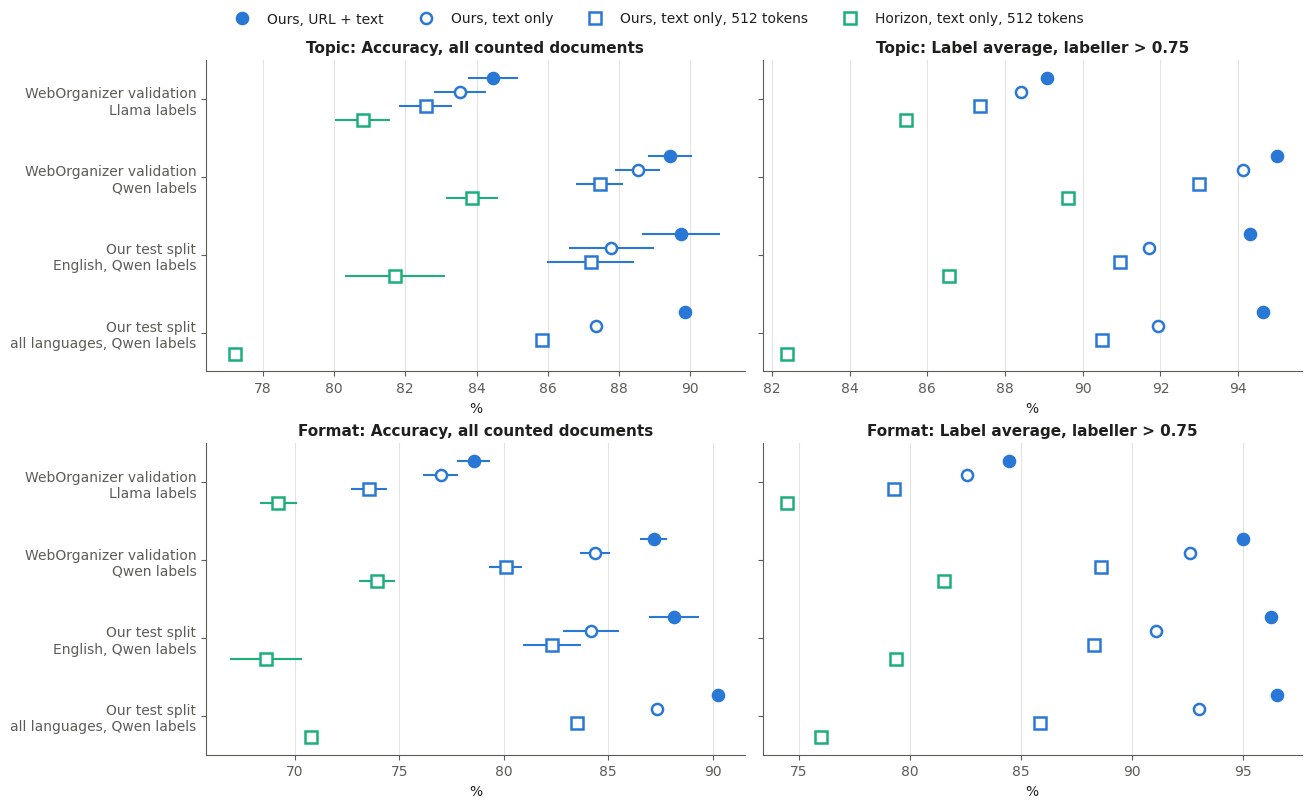

In [6]:
OFFSETS = dict(zip(FOCUS, np.linspace(-0.27, 0.27, len(FOCUS))))
MEASURES = {"Accuracy": "Accuracy, all counted documents", "Label average, labeller > 0.75": "Label average, labeller > 0.75"}
EVALUATION_NAMES = list(EVALUATIONS)

fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout="constrained", sharey=True)
for row, label_type in enumerate(LABEL_TYPES):
    for column, (measure, title) in enumerate(MEASURES.items()):
        ax = axes[row, column]
        for y, evaluation in enumerate(EVALUATION_NAMES):
            for classifier in FOCUS:
                result = SCORES[label_type, evaluation, classifier]
                ax.errorbar(100 * result[measure], y + OFFSETS[classifier],
                            xerr=100 * result["±"] if measure == "Accuracy" else None,
                            ms=8, elinewidth=1.5, capsize=0, linestyle="none", **marker_style(classifier))
        ax.set_yticks(range(len(EVALUATION_NAMES)), [evaluation.replace(", ", "\n", 1) for evaluation in EVALUATION_NAMES])
        ax.set_ylim(len(EVALUATION_NAMES) - 0.5, -0.5)
        ax.grid(axis="y", visible=False)
        ax.set_xlabel("%")
        ax.set_title(f"{label_type.capitalize()}: {title}")
handles = [Line2D([], [], ms=8, linestyle="none", label=classifier, **marker_style(classifier)) for classifier in FOCUS]
fig.legend(handles=handles, loc="outside upper center", ncol=4)
plt.show()

### Ours minus Horizon, paired

The accuracy difference on the same documents between each of our classifiers and Horizon's,
with 95% intervals. Positive values favour ours.

Label type,Evaluation,"Ours, URL + text (points)","Ours, URL + text ±","Ours, text only (points)","Ours, text only ±","Ours, text only, 512 tokens (points)","Ours, text only, 512 tokens ±"
topic,"WebOrganizer validation, Llama labels",+3.6,0.7,+2.7,0.6,+1.8,0.6
topic,"WebOrganizer validation, Qwen labels",+5.6,0.7,+4.7,0.7,+3.6,0.6
topic,"Our test split, English, Qwen labels",+8.0,1.3,+6.1,1.2,+5.5,1.2
topic,"Our test split, all languages, Qwen labels",+12.6,0.1,+10.1,0.1,+8.6,0.1
format,"WebOrganizer validation, Llama labels",+9.3,0.8,+7.8,0.8,+4.3,0.8
format,"WebOrganizer validation, Qwen labels",+13.2,0.9,+10.4,0.8,+6.1,0.8
format,"Our test split, English, Qwen labels",+19.5,1.7,+15.5,1.7,+13.7,1.7
format,"Our test split, all languages, Qwen labels",+19.5,0.2,+16.5,0.2,+12.7,0.2


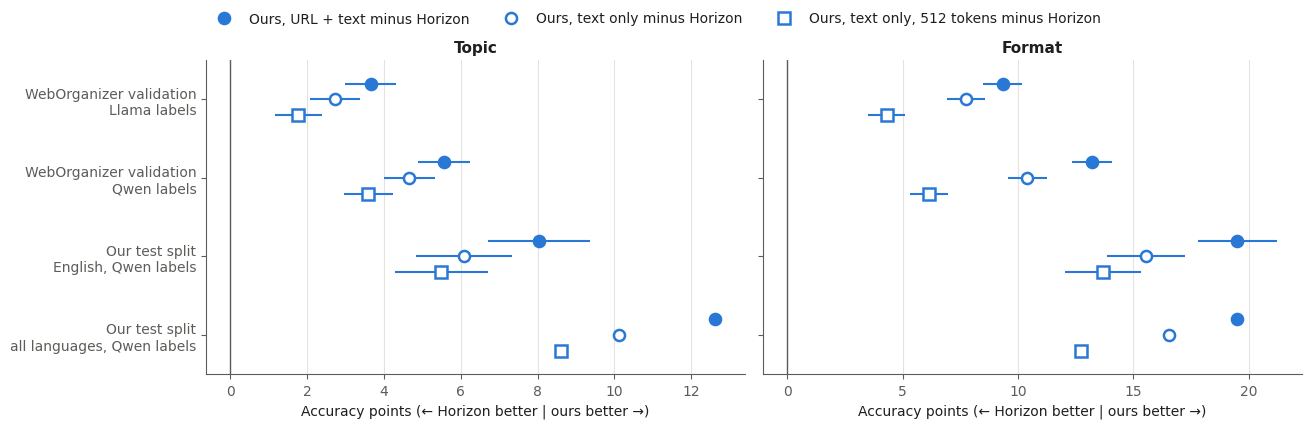

In [7]:
def paired_difference(a: dict, b: dict) -> tuple[float, float]:
    mask = a["_counted"]
    difference = a["_correct"][mask].astype(float) - b["_correct"][mask].astype(float)
    return difference.mean(), 1.96 * difference.std(ddof=1) / math.sqrt(len(difference))


OURS = [classifier for classifier in FOCUS if classifier != HORIZON]
rows = []
for label_type in LABEL_TYPES:
    for evaluation in EVALUATIONS:
        row = {"Label type": label_type, "Evaluation": evaluation}
        for classifier in OURS:
            gain, half = paired_difference(SCORES[label_type, evaluation, classifier], SCORES[label_type, evaluation, HORIZON])
            row[f"{classifier} (points)"] = 100 * gain
            row[f"{classifier} ±"] = 100 * half
        rows.append(row)
DIFFERENCES = pd.DataFrame(rows)
display(DIFFERENCES.style.format({column: "{:+.1f}" for column in DIFFERENCES.columns if column.endswith("(points)")}
                                 | {column: "{:.1f}" for column in DIFFERENCES.columns if column.endswith("±")})
        .hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), layout="constrained", sharey=True)
offsets = dict(zip(OURS, (-0.2, 0.0, 0.2)))
for ax, label_type in zip(axes, LABEL_TYPES):
    frame = DIFFERENCES[DIFFERENCES["Label type"] == label_type].reset_index(drop=True)
    for y, row in frame.iterrows():
        for classifier in OURS:
            ax.errorbar(row[f"{classifier} (points)"], y + offsets[classifier], xerr=row[f"{classifier} ±"], ms=8,
                        elinewidth=1.5, linestyle="none", **marker_style(classifier))
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_yticks(range(len(frame)), [evaluation.replace(", ", "\n", 1) for evaluation in frame["Evaluation"]])
    ax.set_ylim(len(frame) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Accuracy points (← Horizon better | ours better →)")
    ax.set_title(label_type.capitalize())
fig.legend(handles=[Line2D([], [], ms=8, linestyle="none", label=f"{classifier} minus Horizon", **marker_style(classifier))
                    for classifier in OURS], loc="outside upper center", ncol=3)
plt.show()

**Reading section 3:**
- **Against the neutral labeller (Llama-3.1-405B, WebOrganizer validation), ours is ahead in every
  pairing.** Like-for-like (text only, 512 tokens): +1.8 ± 0.6 accuracy points for topic and
  +4.3 ± 0.8 for format (82.6% against 80.8%, 73.5% against 69.2%). Our models as trained (8,192
  tokens) widen the lead: text only +2.7 / +7.8, URL + text +3.6 / +9.3. This is the cleanest
  estimate, but it is English only.
- **Against Qwen's labels from our prompt, the gaps are larger** (at 512 tokens: +3.6 / +6.1 on
  WebOrganizer's pages, +8.6 / +12.7 over all languages of our test split; with URL + text
  +12.6 / +19.5). These labels favour us: same prompt, demonstrations and URL as our training
  labels, and HPLT pages like our training data. Section 7 measures how much of the gap that
  accounts for.
- WebOrganizer's English classifiers remain the best on Llama's labels (87.8% and 84.0% with URL),
  as in `weborganizer_comparison.ipynb`.

## 4. Our test split: per language

Accuracy per language against Qwen's labels (our prompt), duplicates of training left out.
Languages are ranked by Horizon's accuracy; our text-only model at 512 tokens is the like-for-like
comparison.

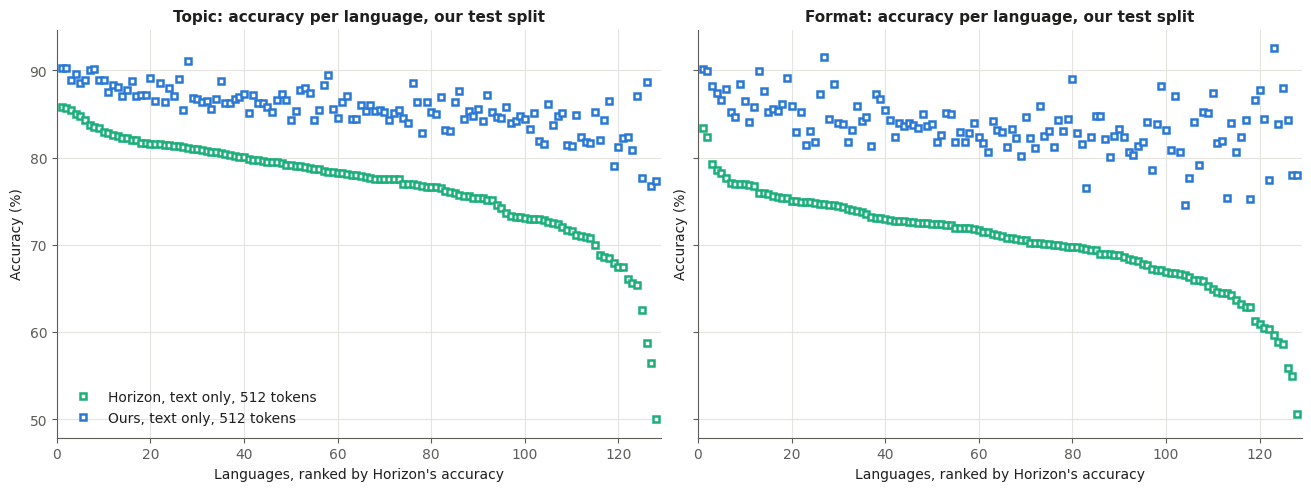

Label type,Languages,Ours (512) ahead by > 2 points,Within 2 points,Horizon ahead by > 2 points,Median difference (points),Horizon median accuracy,Ours (512) median accuracy
topic,128,128,0,0,+7.8,77.9%,85.9%
format,128,128,0,0,+12.0,71.1%,83.9%


**Topic**: the 10 languages where our lead over Horizon (512 tokens) is smallest

,Documents,"Ours, URL + text","Ours, text only","Ours, text only, 512 tokens","Horizon, text only, 512 tokens",Ours (512) minus Horizon
Arabic,"2,914",91.5%,90.2%,88.8%,85.4%,+3.4%
Albanian,"2,921",92.1%,89.6%,88.6%,84.8%,+3.8%
Japanese,"2,885",87.9%,86.7%,85.5%,81.2%,+4.3%
Bosnian,"2,938",92.3%,91.3%,90.2%,85.8%,+4.5%
Thai,"2,903",92.6%,90.6%,89.6%,85.0%,+4.6%
Indonesian,"2,924",91.3%,89.9%,88.9%,84.3%,+4.6%
Spanish,"2,935",90.7%,88.6%,87.5%,82.8%,+4.7%
North Azerbaijani,"2,909",93.4%,91.3%,90.3%,85.6%,+4.7%
Danish,"2,920",90.9%,87.9%,87.1%,82.3%,+4.8%
Malay,"2,893",89.2%,86.6%,85.6%,80.6%,+4.9%


**Topic**: the 10 languages where our lead over Horizon (512 tokens) is largest

,Documents,"Ours, URL + text","Ours, text only","Ours, text only, 512 tokens","Horizon, text only, 512 tokens",Ours (512) minus Horizon
Occitan,"2,944",92.3%,90.2%,88.7%,58.7%,+29.9%
Yiddish,"2,928",86.6%,81.8%,77.3%,50.0%,+27.3%
Tibetan,"1,686",91.2%,88.5%,87.1%,65.4%,+21.6%
Magahi,464,88.6%,77.4%,76.7%,56.5%,+20.3%
Odia,"2,946",90.7%,88.6%,86.5%,68.5%,+18.0%
Latgalian,"1,630",88.0%,83.7%,82.4%,66.1%,+16.3%
Lao,"2,927",90.8%,89.3%,84.4%,68.6%,+15.7%
Kabuverdianu,780,90.3%,81.7%,80.9%,65.6%,+15.3%
Faroese,"2,892",88.1%,86.4%,85.2%,70.0%,+15.2%
Banjar Arabic,579,87.7%,77.5%,77.7%,62.5%,+15.2%


**Format**: the 10 languages where our lead over Horizon (512 tokens) is smallest

,Documents,"Ours, URL + text","Ours, text only","Ours, text only, 512 tokens","Horizon, text only, 512 tokens",Ours (512) minus Horizon
Tajik,"2,799",91.2%,88.7%,81.5%,74.9%,+6.6%
Nepali,"2,791",93.3%,91.8%,90.1%,83.4%,+6.7%
Serbian Latin,"2,886",89.4%,87.0%,81.8%,74.8%,+7.0%
Sinhala,"2,866",90.3%,86.7%,76.5%,69.5%,+7.0%
Kannada,"2,845",91.4%,89.3%,84.1%,76.9%,+7.2%
Odia,"2,916",95.1%,93.8%,89.9%,82.3%,+7.6%
Malayalam,"2,877",92.4%,89.5%,84.6%,77.0%,+7.6%
Croatian,"2,898",89.4%,86.4%,81.8%,74.1%,+7.7%
Tatar,"2,708",90.3%,87.7%,83.0%,75.0%,+8.0%
Burmese,"2,781",87.7%,84.7%,74.6%,66.6%,+8.0%


**Format**: the 10 languages where our lead over Horizon (512 tokens) is largest

,Documents,"Ours, URL + text","Ours, text only","Ours, text only, 512 tokens","Horizon, text only, 512 tokens",Ours (512) minus Horizon
Banjar Arabic,603,94.9%,93.2%,92.5%,59.7%,+32.8%
Minangkabau,"2,123",92.0%,89.0%,87.9%,58.6%,+29.3%
Occitan,"2,869",90.0%,87.2%,84.3%,55.9%,+28.4%
Yiddish,"2,855",87.3%,84.7%,78.0%,50.6%,+27.4%
Magahi,523,92.9%,91.0%,87.8%,61.0%,+26.8%
Banjar Latin,"1,800",91.8%,87.3%,86.6%,61.3%,+25.3%
Sundanese,"2,769",89.2%,87.4%,83.9%,58.9%,+25.0%
Tibetan,"1,598",89.4%,87.9%,84.4%,60.5%,+23.9%
Tok Pisin,"1,180",87.8%,84.8%,78.1%,55.0%,+23.1%
Balinese,"2,046",90.5%,88.3%,87.4%,65.0%,+22.4%


In [8]:
def per_language_accuracy(label_type: str) -> pd.DataFrame:
    data = HPLT[label_type]
    top = data["targets"]["qwen"].argmax(axis=1)
    counted = data["keep"] & (top < 24)
    frame = pd.DataFrame({"language": data["docs"]["language"].to_numpy()[counted]})
    for classifier in FOCUS:
        frame[classifier] = data["predictions"][classifier][counted] == top[counted]
    table = frame.groupby("language").mean()
    table.insert(0, "Documents", frame.groupby("language").size())
    table["Ours (512) minus Horizon"] = table["Ours, text only, 512 tokens"] - table[HORIZON]
    table.index = [LANGUAGE_NAMES.get(language, language) for language in table.index]
    return table


PER_LANGUAGE = {label_type: per_language_accuracy(label_type) for label_type in LABEL_TYPES}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained", sharey=True)
for ax, label_type in zip(axes, LABEL_TYPES):
    table = 100 * PER_LANGUAGE[label_type].drop(columns="Documents").sort_values(HORIZON, ascending=False)
    rank = np.arange(1, len(table) + 1)
    for classifier in (HORIZON, "Ours, text only, 512 tokens"):
        ax.plot(rank, table[classifier], ms=4.5, linestyle="none", label=classifier, **marker_style(classifier))
    ax.set_xlim(0, len(table) + 1)
    ax.set_xlabel("Languages, ranked by Horizon's accuracy")
    ax.set_ylabel("Accuracy (%)")
    ax.set_title(f"{label_type.capitalize()}: accuracy per language, our test split")
axes[0].legend(loc="lower left")
plt.show()

rows = []
for label_type in LABEL_TYPES:
    table = PER_LANGUAGE[label_type]
    difference = table["Ours (512) minus Horizon"]
    rows.append({"Label type": label_type, "Languages": len(table),
                 "Ours (512) ahead by > 2 points": int((difference > 0.02).sum()),
                 "Within 2 points": int((difference.abs() <= 0.02).sum()),
                 "Horizon ahead by > 2 points": int((difference < -0.02).sum()),
                 "Median difference (points)": 100 * difference.median(),
                 "Horizon median accuracy": table[HORIZON].median(),
                 "Ours (512) median accuracy": table["Ours, text only, 512 tokens"].median()})
display(pd.DataFrame(rows).style.format({"Median difference (points)": "{:+.1f}", "Horizon median accuracy": "{:.1%}",
                                         "Ours (512) median accuracy": "{:.1%}"}).hide(axis="index"))

for label_type in LABEL_TYPES:
    ranked = PER_LANGUAGE[label_type].sort_values("Ours (512) minus Horizon")
    for title, table in (("smallest", ranked.head(10)), ("largest", ranked.tail(10).iloc[::-1])):
        display(Markdown(f"**{label_type.capitalize()}**: the 10 languages where our lead over Horizon (512 tokens) is {title}"))
        display(table.style.format({column: "{:.1%}" for column in FOCUS} | {"Documents": "{:,}",
                                                                            "Ours (512) minus Horizon": "{:+.1%}"}))

**Reading section 4:**
- **Ours (text only, 512 tokens) is more than 2 points ahead in all 128 languages** for both label
  types; the median lead is +7.8 (topic) and +12.0 (format) points.
- The smallest leads are in large languages (topic: Arabic +3.4, Albanian +3.8, Japanese +4.3,
  Bosnian, Thai, Indonesian, Spanish about +4.5), which are probably among Horizon's 66 training
  languages. The largest are in small languages that probably are not (topic: Occitan +29.9,
  Yiddish +27.3, Tibetan +21.6, Magahi +20.3; format: Banjar Arabic +32.8, Minangkabau +29.3,
  Occitan +28.4). Their language list isn't published, so this is an inference, not a check.

## 5. Our test split: per quality bucket and per label

Quality buckets are HPLT's (clean, noisy, poor). Per-label accuracy counts the documents where
Qwen > 0.75, all languages.

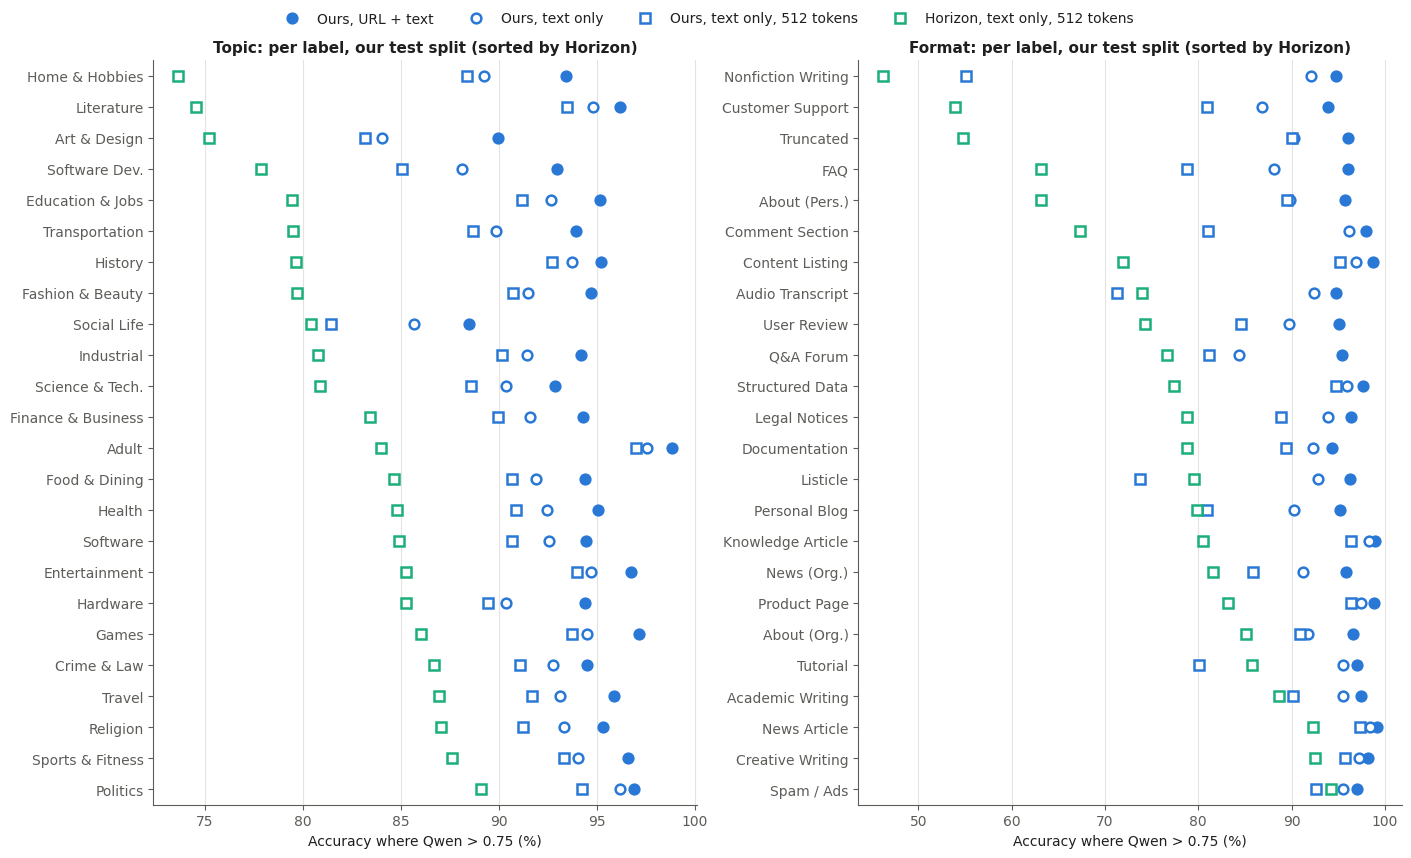

In [9]:
rows = {}
for label_type in LABEL_TYPES:
    data = HPLT[label_type]
    targets = data["targets"]["qwen"]
    for source in ("clean_random", "noisy_random", "poor_random"):
        mask = data["keep"] & (data["docs"]["source"] == source).to_numpy()
        for classifier in FOCUS:
            result = score(data["predictions"][classifier], targets, mask)
            rows[label_type, source, classifier] = {key: result[key] for key in
                                                    ("Documents", "Accuracy", "Label average", "Accuracy, labeller > 0.75",
                                                     "Label average, labeller > 0.75")}
by_source = pd.DataFrame.from_dict(rows, orient="index")
by_source.index.names = ["Label type", "Source", "Classifier"]
show_scores(by_source, ["Accuracy", "Label average", "Accuracy, labeller > 0.75", "Label average, labeller > 0.75"],
            level=["Label type", "Source"])

fig, axes = plt.subplots(1, 2, figsize=(14, 8.5), layout="constrained")
for ax, label_type in zip(axes, LABEL_TYPES):
    evaluation = "Our test split, all languages, Qwen labels"
    table = pd.DataFrame({classifier: SCORES[label_type, evaluation, classifier]["_per_label_sure"] for classifier in FOCUS})
    table.index = [LABELS[label_type][index] for index in table.index]
    table = table.sort_values(HORIZON)
    y = np.arange(len(table))
    for classifier in FOCUS:
        ax.plot(100 * table[classifier], y, ms=7, linestyle="none", label=classifier, **marker_style(classifier))
    ax.set_yticks(y, table.index)
    ax.set_ylim(len(table) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Accuracy where Qwen > 0.75 (%)")
    ax.set_title(f"{label_type.capitalize()}: per label, our test split (sorted by Horizon)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=4)
plt.show()

**Reading section 5:**
- Horizon loses most on HPLT's poor bucket (topic 65.8% against 81.4% on clean pages; format
  63.8% against 75.2%), more than ours at 512 tokens (79.9% against 87.5%; 85.9% against 82.0%).
  With the URL, ours is almost as accurate on poor pages as on clean ones.
- Horizon's weakest labels against Qwen are *Home & Hobbies*, *Literature* and *Art & Design*
  (topic, 74–75%) and *Nonfiction Writing*, *Customer Support* and *Truncated* (format, 46–55%).
- Our 512-token model loses most on *Nonfiction Writing* (55%, against 92% at full length) and
  *Listicle* and *Audio Transcript*: labels that depend on how the page continues.

## 6. How much does the 512-token cut cost?

Our text-only model at 8,192 and at 512 tokens, and Horizon's, by document length (characters,
which is what the dataset stores; 512 mmBERT tokens are very roughly 2,000 characters of
English). Our test split, all languages, Qwen labels.

Label type,Characters,Documents,"Ours, text only","Ours, text only, 512 tokens","Horizon, text only, 512 tokens"
topic,< 1K,"194,062",84.6%,84.6%,74.2%
topic,1–2K,"65,896",89.9%,88.8%,81.9%
topic,2–4K,"49,708",91.0%,87.5%,81.2%
topic,4–8K,"25,850",91.9%,85.7%,80.2%
topic,8–16K,"9,570",92.0%,83.9%,78.5%
topic,16–32K,"3,298",91.0%,83.9%,78.5%
topic,≥ 32K,"1,779",88.6%,81.4%,76.1%
format,< 1K,"180,719",86.1%,86.0%,69.0%
format,1–2K,"66,424",90.2%,87.8%,78.5%
format,2–4K,"50,090",88.5%,80.5%,73.0%


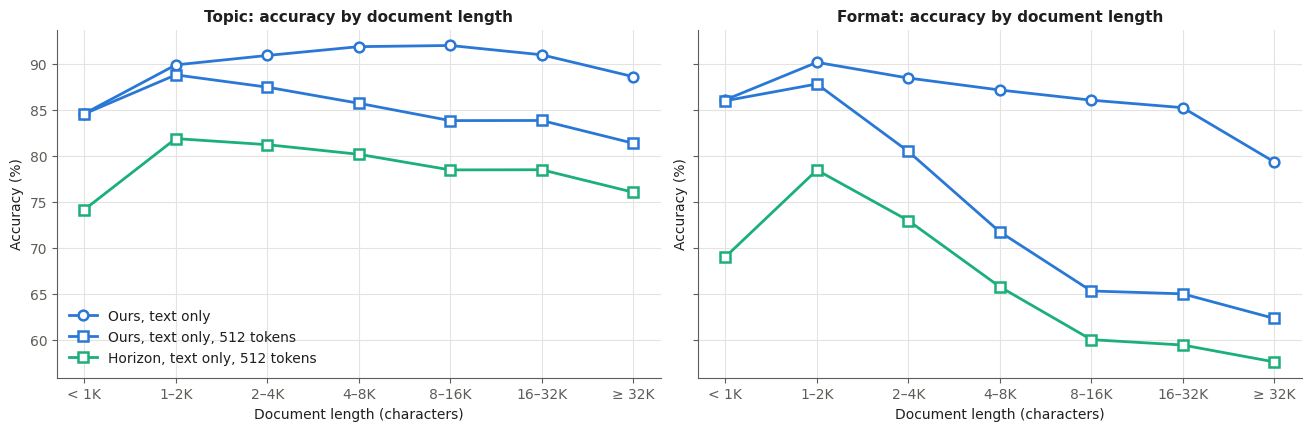

In [10]:
BINS = [0, 1_000, 2_000, 4_000, 8_000, 16_000, 32_000, np.inf]
BIN_NAMES = ["< 1K", "1–2K", "2–4K", "4–8K", "8–16K", "16–32K", "≥ 32K"]
LENGTH_CLASSIFIERS = ["Ours, text only", "Ours, text only, 512 tokens", HORIZON]

rows = []
for label_type in LABEL_TYPES:
    data = HPLT[label_type]
    result = SCORES[label_type, "Our test split, all languages, Qwen labels", "Ours, text only"]
    counted = result["_counted"]
    length_bin = pd.cut(data["characters"], BINS, labels=BIN_NAMES, right=False)
    for name in BIN_NAMES:
        mask = counted & (length_bin == name)
        row = {"Label type": label_type, "Characters": name, "Documents": int(mask.sum())}
        for classifier in LENGTH_CLASSIFIERS:
            row[classifier] = SCORES[label_type, "Our test split, all languages, Qwen labels", classifier]["_correct"][mask].mean()
        rows.append(row)
BY_LENGTH = pd.DataFrame(rows)
display(BY_LENGTH.style.format({classifier: "{:.1%}" for classifier in LENGTH_CLASSIFIERS} | {"Documents": "{:,}"})
        .hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), layout="constrained", sharey=True)
for ax, label_type in zip(axes, LABEL_TYPES):
    frame = BY_LENGTH[BY_LENGTH["Label type"] == label_type]
    x = np.arange(len(frame))
    for classifier in LENGTH_CLASSIFIERS:
        style = marker_style(classifier)
        ax.plot(x, 100 * frame[classifier], ms=7, lw=2, label=classifier, **style)
    ax.set_xticks(x, frame["Characters"])
    ax.set_xlabel("Document length (characters)")
    ax.set_ylabel("Accuracy (%)")
    ax.set_title(f"{label_type.capitalize()}: accuracy by document length")
axes[0].legend(loc="lower left")
plt.show()

**Reading section 6:**
- **Cutting our text-only model to 512 tokens costs 1.5 (topic) and 3.8 (format) accuracy points**
  over all languages (0.9 and 3.5 on Llama's labels), and nothing on pages under 1,000
  characters. Format suffers on long pages: 87.2% → 71.7% at 4–8K characters.
- This overstates what a model *trained* at 512 tokens would lose: ours was trained on up to
  8,192 tokens, with labels made from up to 8,192 tokens, so the cut is a distribution shift for
  it. Qwen's labels for long pages also rest on more text than any 512-token model sees.
- **Context length explains only a small part of the gap to Horizon.** On pages under 1,000
  characters, where neither model loses anything to the cut, ours still leads by 10.4 (topic,
  84.6% against 74.2%) and 17.0 (format, 86.0% against 69.0%) points against our Qwen labels.
  The rest comes from training data (size, languages, HPLT pages), the teacher prompt, and the
  targets sharing our prompt; the planned labellers will separate the last of these.

## 7. Home, away and neutral: three labellers on the same pages

19,200 pages of our test split, 150 per language in all 128 languages, drawn at random by
`sample_cross_labeller_eval.py` (duplicates of our training pages left out), labelled by:

- **Qwen3.8-27B, our prompt:** our training labels' setup (favours ours);
- **Qwen3.8-27B-FP8, Horizon's prompt:** their `teacher_webtax.py`, unchanged, as for their
  training labels (favours Horizon);
- **gemma-4-31B-it, Horizon's protocol:** the same script with their independent judge (neither
  system trained on it).

Horizon's labellers have no *Other* or *Bad example*; for our prompt, pages whose top label is
one of them are left out as before, so that column counts somewhat fewer pages. Gemma gives its
top label > 0.75 on almost every page, so its "labeller > 0.75" columns cover nearly all pages.

In [11]:
import sys
sys.path.insert(0, str(REPO / "scripts/model_evaluation"))
from predict_horizon import SLUGS  # our 24 label names -> Horizon's output names

LABELLERS = {"qwen_ours": "Qwen3.8-27B, our prompt", "qwen_horizon": "Qwen3.8-27B-FP8, Horizon's prompt",
             "gemma": "gemma-4-31B-it, Horizon's protocol"}
LABELLER_FAVOURS = {"qwen_ours": "favours ours", "qwen_horizon": "favours Horizon", "gemma": "neutral"}

sample = pd.read_parquet(CROSS_SAMPLE, columns=["position", "id", "language"])
CROSS = {}
for label_type in LABEL_TYPES:
    docs = HPLT[label_type]["docs"]
    positions = sample["position"].to_numpy()
    if not (docs["id"].to_numpy()[positions] == sample["id"].to_numpy()).all():
        raise ValueError(f"{CROSS_SAMPLE}: positions don't match the {label_type} test split")
    names = LABELS[label_type]
    targets = {"qwen_ours": HPLT[label_type]["targets"]["qwen"][positions]}
    for labeller, directory in (("qwen_horizon", "qwen"), ("gemma", "gemma")):
        path = HORIZON_WEBTAX / directory / "hplt-test-150/shard-0-of-1.parquet"
        frame = pd.read_parquet(path)
        if not (frame["id"].to_numpy() == sample["id"].to_numpy()).all():
            raise ValueError(f"{path}: pages differ from the sample")
        columns = [f"{label_type}_{SLUGS[label_type][name]}" for name in names[:24]]
        probs = frame[columns].to_numpy(dtype=np.float64)
        if not np.isfinite(probs).all() or not np.allclose(probs.sum(axis=1), 1, atol=1e-6):
            raise ValueError(f"{path}: {label_type} probabilities are missing or don't sum to 1")
        # Our 26-label order, with 0 for Other and Bad example.
        targets[labeller] = np.hstack([probs, np.zeros((len(probs), len(names) - 24))])
    CROSS[label_type] = {"targets": targets, "language": sample["language"].to_numpy(),
                         "predictions": {name: HPLT[label_type]["predictions"][name][positions] for name in CLASSIFIERS}}
print(f"{len(sample):,} pages in {sample['language'].nunique()} languages")

19,200 pages in 128 languages


In [12]:
rows = []
for label_type in LABEL_TYPES:
    targets = CROSS[label_type]["targets"]
    for a, b in (("qwen_ours", "qwen_horizon"), ("qwen_ours", "gemma"), ("qwen_horizon", "gemma")):
        top_a, top_b = targets[a].argmax(axis=1), targets[b].argmax(axis=1)
        both_sure = (targets[a].max(axis=1) > CONFIDENCE) & (targets[b].max(axis=1) > CONFIDENCE)
        counted = (top_a < 24) & (top_b < 24)
        rows.append({"Label type": label_type, "Labellers": f"{LABELLERS[a]} / {LABELLERS[b]}",
                     "Same top label": (top_a == top_b)[counted].mean(),
                     "Same top label, both > 0.75": (top_a == top_b)[counted & both_sure].mean()})
display(pd.DataFrame(rows).style.format({"Same top label": "{:.1%}", "Same top label, both > 0.75": "{:.1%}"})
        .hide(axis="index"))
rows = [{"Label type": label_type, "Labeller": LABELLERS[labeller],
         "Top label > 0.75": (CROSS[label_type]["targets"][labeller].max(axis=1) > CONFIDENCE).mean(),
         "Top label ≥ 0.99": (CROSS[label_type]["targets"][labeller].max(axis=1) >= 0.99).mean()}
        for label_type in LABEL_TYPES for labeller in LABELLERS]
display(pd.DataFrame(rows).style.format({"Top label > 0.75": "{:.1%}", "Top label ≥ 0.99": "{:.1%}"}).hide(axis="index"))

Label type,Labellers,Same top label,"Same top label, both > 0.75"
topic,"Qwen3.8-27B, our prompt / Qwen3.8-27B-FP8, Horizon's prompt",87.5%,97.4%
topic,"Qwen3.8-27B, our prompt / gemma-4-31B-it, Horizon's protocol",86.2%,93.0%
topic,"Qwen3.8-27B-FP8, Horizon's prompt / gemma-4-31B-it, Horizon's protocol",86.6%,94.7%
format,"Qwen3.8-27B, our prompt / Qwen3.8-27B-FP8, Horizon's prompt",76.4%,94.2%
format,"Qwen3.8-27B, our prompt / gemma-4-31B-it, Horizon's protocol",74.6%,86.4%
format,"Qwen3.8-27B-FP8, Horizon's prompt / gemma-4-31B-it, Horizon's protocol",77.1%,88.4%


Label type,Labeller,Top label > 0.75,Top label ≥ 0.99
topic,"Qwen3.8-27B, our prompt",82.2%,50.5%
topic,"Qwen3.8-27B-FP8, Horizon's prompt",81.0%,53.1%
topic,"gemma-4-31B-it, Horizon's protocol",98.0%,92.1%
format,"Qwen3.8-27B, our prompt",69.5%,31.4%
format,"Qwen3.8-27B-FP8, Horizon's prompt",72.3%,37.2%
format,"gemma-4-31B-it, Horizon's protocol",97.3%,87.7%


In [13]:
CROSS_SCORES = {}
for label_type in LABEL_TYPES:
    everyone = np.ones(len(CROSS[label_type]["language"]), dtype=bool)
    for labeller in LABELLERS:
        for classifier in CLASSIFIERS:
            CROSS_SCORES[label_type, labeller, classifier] = score(
                CROSS[label_type]["predictions"][classifier], CROSS[label_type]["targets"][labeller], everyone)

for label_type in LABEL_TYPES:
    rows = {(f"{LABELLERS[labeller]} ({LABELLER_FAVOURS[labeller]})", classifier):
            {key: value for key, value in CROSS_SCORES[label_type, labeller, classifier].items() if not key.startswith("_")}
            for labeller in LABELLERS for classifier in CLASSIFIERS}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.names = ["Labeller", "Classifier"]
    display(Markdown(f"**{label_type.capitalize()}**"))
    show_scores(table, BEST_COLUMNS, level="Labeller")

**Topic**

**Format**

### Ours minus Horizon, by labeller

Paired accuracy differences on the same pages, with 95% intervals.

Label type,Labeller,"Ours, URL + text (points)","Ours, URL + text ±","Ours, text only (points)","Ours, text only ±","Ours, text only, 512 tokens (points)","Ours, text only, 512 tokens ±"
topic,"Qwen3.8-27B, our prompt (favours ours)",+13.8,0.6,+10.7,0.6,+9.2,0.6
topic,"Qwen3.8-27B-FP8, Horizon's prompt (favours Horizon)",+5.2,0.6,+5.0,0.6,+4.2,0.6
topic,"gemma-4-31B-it, Horizon's protocol (neutral)",+6.6,0.6,+6.6,0.6,+5.4,0.6
format,"Qwen3.8-27B, our prompt (favours ours)",+20.2,0.7,+17.1,0.7,+13.1,0.7
format,"Qwen3.8-27B-FP8, Horizon's prompt (favours Horizon)",-1.0,0.7,-0.2,0.7,-1.9,0.7
format,"gemma-4-31B-it, Horizon's protocol (neutral)",+1.9,0.7,+2.9,0.7,+1.2,0.7


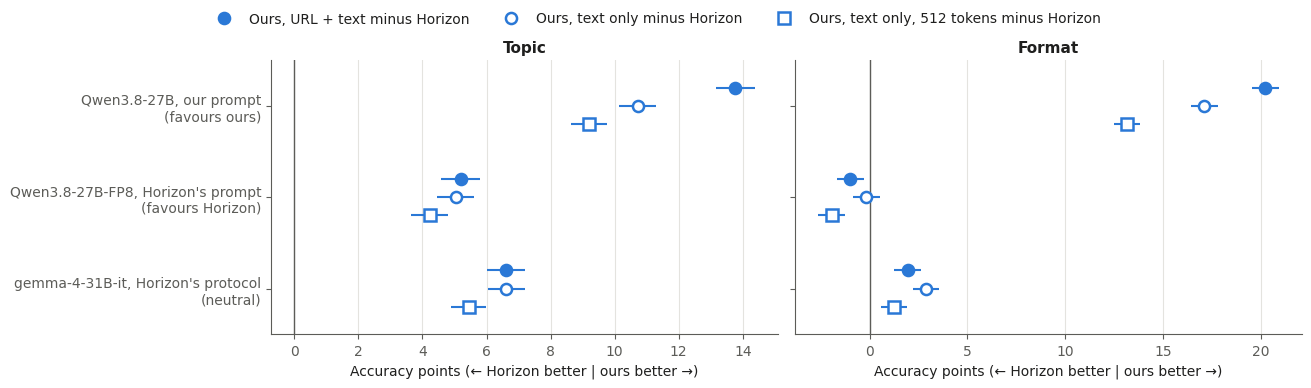

In [14]:
rows = []
for label_type in LABEL_TYPES:
    for labeller in LABELLERS:
        row = {"Label type": label_type, "Labeller": f"{LABELLERS[labeller]} ({LABELLER_FAVOURS[labeller]})"}
        for classifier in OURS:
            gain, half = paired_difference(CROSS_SCORES[label_type, labeller, classifier],
                                           CROSS_SCORES[label_type, labeller, HORIZON])
            row[f"{classifier} (points)"] = 100 * gain
            row[f"{classifier} ±"] = 100 * half
        rows.append(row)
CROSS_DIFFERENCES = pd.DataFrame(rows)
display(CROSS_DIFFERENCES.style.format({column: "{:+.1f}" for column in CROSS_DIFFERENCES.columns if column.endswith("(points)")}
                                       | {column: "{:.1f}" for column in CROSS_DIFFERENCES.columns if column.endswith("±")})
        .hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), layout="constrained", sharey=True)
for ax, label_type in zip(axes, LABEL_TYPES):
    frame = CROSS_DIFFERENCES[CROSS_DIFFERENCES["Label type"] == label_type].reset_index(drop=True)
    for y, row in frame.iterrows():
        for classifier in OURS:
            ax.errorbar(row[f"{classifier} (points)"], y + offsets[classifier], xerr=row[f"{classifier} ±"], ms=8,
                        elinewidth=1.5, linestyle="none", **marker_style(classifier))
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_yticks(range(len(frame)), [labeller.replace(" (", "\n(") for labeller in frame["Labeller"]])
    ax.set_ylim(len(frame) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Accuracy points (← Horizon better | ours better →)")
    ax.set_title(label_type.capitalize())
fig.legend(handles=[Line2D([], [], ms=8, linestyle="none", label=f"{classifier} minus Horizon", **marker_style(classifier))
                    for classifier in OURS], loc="outside upper center", ncol=3)
plt.show()

### Per language, against the neutral judge

Accuracy difference per language (ours, text only at 512 tokens, minus Horizon) against
gemma-4-31B-it, 150 pages per language, with 95% intervals of the paired difference. Languages
are ranked by the difference; the table counts languages for every labeller.

Label type,Labeller,Ours (512) clearly ahead,Not clearly different,Horizon clearly ahead,Median difference (points)
topic,"Qwen3.8-27B, our prompt (favours ours)",93,35,0,+8.3
topic,"Qwen3.8-27B-FP8, Horizon's prompt (favours Horizon)",32,95,1,+4.0
topic,"gemma-4-31B-it, Horizon's protocol (neutral)",51,76,1,+5.3
format,"Qwen3.8-27B, our prompt (favours ours)",105,23,0,+11.8
format,"Qwen3.8-27B-FP8, Horizon's prompt (favours Horizon)",7,104,17,-2.7
format,"gemma-4-31B-it, Horizon's protocol (neutral)",10,112,6,+1.0


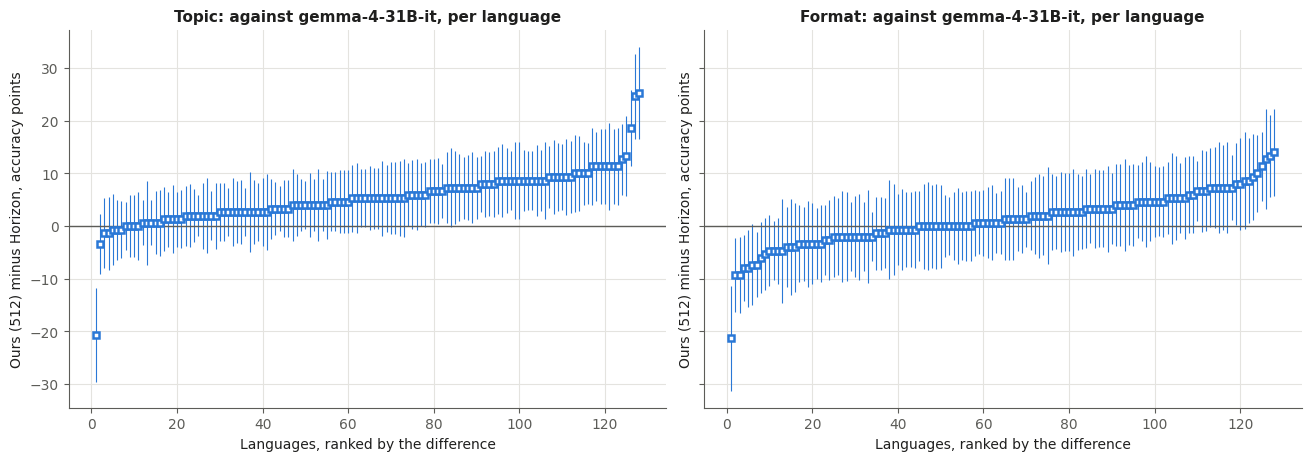

**Topic**: the 10 languages where Horizon does best relative to ours, against gemma

,Pages,Difference,±
Occitan,150,-20.7%,8.9%
Tamil,150,-3.3%,5.7%
Esperanto,150,-1.3%,6.7%
Kabuverdianu,150,-1.3%,6.9%
Lombard,150,-0.7%,6.8%
Mongolian,150,-0.7%,5.7%
Turkish,150,-0.7%,5.4%
Bosnian,150,+0.0%,4.5%
Finnish,150,+0.0%,5.9%
Cebuano,150,+0.0%,5.9%


**Format**: the 10 languages where Horizon does best relative to ours, against gemma

,Pages,Difference,±
Occitan,150,-21.3%,9.9%
Cantonese,150,-9.3%,7.0%
Romanian,150,-9.3%,7.3%
Kannada,150,-8.0%,6.3%
Lithuanian,150,-8.0%,7.3%
Bengali,150,-7.3%,7.7%
Armenian,150,-7.3%,6.2%
Mongolian,150,-6.0%,6.7%
Serbian Latin,150,-5.3%,6.9%
Finnish,150,-4.7%,6.8%


In [15]:
def per_language_differences(label_type: str, labeller: str, classifier: str) -> pd.DataFrame:
    data = CROSS[label_type]
    top = data["targets"][labeller].argmax(axis=1)
    counted = top < 24
    difference = ((data["predictions"][classifier] == top).astype(float)
                  - (data["predictions"][HORIZON] == top).astype(float))
    frame = pd.DataFrame({"language": data["language"][counted], "difference": difference[counted]})
    grouped = frame.groupby("language")["difference"]
    table = pd.DataFrame({"Pages": grouped.size(), "Difference": grouped.mean(),
                          "±": 1.96 * grouped.std(ddof=1) / np.sqrt(grouped.size())})
    table.index = [LANGUAGE_NAMES.get(language, language) for language in table.index]
    return table.sort_values("Difference")


rows = []
for label_type in LABEL_TYPES:
    for labeller in LABELLERS:
        table = per_language_differences(label_type, labeller, "Ours, text only, 512 tokens")
        low, high = table["Difference"] - table["±"], table["Difference"] + table["±"]
        rows.append({"Label type": label_type, "Labeller": f"{LABELLERS[labeller]} ({LABELLER_FAVOURS[labeller]})",
                     "Ours (512) clearly ahead": int((low > 0).sum()), "Not clearly different": int(((low <= 0) & (high >= 0)).sum()),
                     "Horizon clearly ahead": int((high < 0).sum()), "Median difference (points)": 100 * table["Difference"].median()})
display(pd.DataFrame(rows).style.format({"Median difference (points)": "{:+.1f}"}).hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained", sharey=True)
GEMMA_LANGUAGES = {}
for ax, label_type in zip(axes, LABEL_TYPES):
    table = per_language_differences(label_type, "gemma", "Ours, text only, 512 tokens")
    GEMMA_LANGUAGES[label_type] = table
    rank = np.arange(1, len(table) + 1)
    ax.errorbar(rank, 100 * table["Difference"], yerr=100 * table["±"], ms=4.5, elinewidth=0.8, linestyle="none",
                **marker_style("Ours, text only, 512 tokens"))
    ax.axhline(0, color=MUTED, lw=1)
    ax.set_xlabel("Languages, ranked by the difference")
    ax.set_ylabel("Ours (512) minus Horizon, accuracy points")
    ax.set_title(f"{label_type.capitalize()}: against gemma-4-31B-it, per language")
plt.show()

for label_type in LABEL_TYPES:
    display(Markdown(f"**{label_type.capitalize()}**: the 10 languages where Horizon does best relative to ours, against gemma"))
    display(GEMMA_LANGUAGES[label_type].head(10).style.format({"Difference": "{:+.1%}", "±": "{:.1%}"}))

**Reading section 7:**
- **The prompt alone changes many labels:** the same Qwen model gives a different top label on
  12.5% (topic) and 23.6% (format) of the pages with our prompt and with Horizon's. Gemma agrees
  about equally with both (topic 86.2% and 86.6%; format 74.6% and 77.1%, slightly closer to
  Horizon's prompt, as their model card says). Gemma is overconfident: its top label is ≥ 0.99 on
  about 90% of the pages, so its "labeller > 0.75" columns are close to its all-page columns.
- **Topic: ours is ahead against every labeller, including Horizon's own.** Like-for-like (text
  only, 512 tokens): +9.2 (our prompt), +4.2 (Horizon's prompt) and **+5.4 ± 0.6** (gemma)
  accuracy points; at full length +6.6 against gemma. Against gemma, ours is clearly ahead in 51
  languages and clearly behind in one (Occitan, below).
- **Format: most of the earlier lead came from our prompt.** Like-for-like: +13.1 (our prompt),
  −1.9 ± 0.7 (Horizon's prompt, Horizon slightly ahead) and **+1.2 ± 0.7** (gemma); our text-only
  model at full length +2.9 ± 0.7 against gemma. Per language against gemma: ours clearly ahead in
  10, Horizon in 6, the rest not clearly different.
- **The URL helps reproduce labels that saw the URL, not others.** Against the URL-blind
  labellers, our URL model gains nothing on topic (82.0% against 82.0% for text only, gemma)
  and loses slightly on format (71.1% against 72.0%). Whether URL-aware labels are *better* is a
  question for human labels. Occitan shows a case where the URL is right: 23% of the Occitan test
  pages are French escort-site spam whose text is a list of French town names (HPLT's language
  identification calls them Occitan). With the URL, our Qwen labels them *Adult*; Horizon's
  URL-blind labellers call them *History*. Our classifiers learned the pattern, even without the
  URL, so in Occitan they lose about 21 points to Horizon against gemma.
- **Domain:** these are HPLT pages, the source of our training data; a FineWeb-2 sample would be
  Horizon's home ground.

## 8. Ten major languages both systems were trained on

Horizon's 66 training languages are not published, but their `training/data_stats.json` lists
12,000 FineWeb (English) pages and 129,965 FineWeb-2 pages, about 2,000 for each of 65
languages. This section keeps to ten languages that are surely among them: **English** and
**FineWeb-2's nine largest subsets** (Russian, Mandarin Chinese, German, Japanese, Spanish,
French, Italian, Portuguese and Polish; Mandarin is our Simplified Chinese). All ten are also
among our 128 training languages.

150 pages per language (section 7) are too few for per-language results, so 1,000 more pages
per language were drawn from our test split (`sample_cross_labeller_eval.py --languages ...
--exclude_samples hplt-test-150/sample.parquet`, so no page is drawn twice; duplicates of our
training pages left out) and labelled the same way with Horizon's script (Qwen and gemma). The
section scores the 11,500 pages of both samples together, 1,150 per language.

In [16]:
MAJOR_LANGUAGES = ["english", "russian", "simplified_chinese", "german", "japanese", "spanish", "french", "italian",
                   "portuguese", "polish"]
FOLLOW_UP_SAMPLE = REPO / "results/statistics/cross_labeller/hplt-test-major10-1000/sample.parquet"

follow_up = pd.read_parquet(FOLLOW_UP_SAMPLE, columns=["position", "id", "language"])
if set(follow_up["language"]) != set(MAJOR_LANGUAGES):
    raise ValueError(f"{FOLLOW_UP_SAMPLE}: languages {sorted(set(follow_up['language']))}")
first = sample[sample["language"].isin(MAJOR_LANGUAGES)]
major_pages = pd.concat([first.assign(part="section 7 sample"), follow_up.assign(part="follow-up")], ignore_index=True)
if major_pages["id"].duplicated().any():
    raise ValueError("the follow-up sample repeats pages of the section 7 sample")

MAJOR = {}
for label_type in LABEL_TYPES:
    docs = HPLT[label_type]["docs"]
    positions = major_pages["position"].to_numpy()
    if not (docs["id"].to_numpy()[positions] == major_pages["id"].to_numpy()).all():
        raise ValueError(f"positions don't match the {label_type} test split")
    names = LABELS[label_type]
    targets = {"qwen_ours": HPLT[label_type]["targets"]["qwen"][positions]}
    for labeller, directory in (("qwen_horizon", "qwen"), ("gemma", "gemma")):
        frames = []
        for sample_name, sample_ids in (("hplt-test-150", sample["id"]), ("hplt-test-major10-1000", follow_up["id"])):
            path = HORIZON_WEBTAX / directory / sample_name / "shard-0-of-1.parquet"
            frame = pd.read_parquet(path)
            if not (frame["id"].to_numpy() == sample_ids.to_numpy()).all():
                raise ValueError(f"{path}: pages differ from the sample")
            frames.append(frame.set_index("id"))
        frame = pd.concat(frames).loc[major_pages["id"]]
        probs = frame[[f"{label_type}_{SLUGS[label_type][name]}" for name in names[:24]]].to_numpy(dtype=np.float64)
        if not np.isfinite(probs).all() or not np.allclose(probs.sum(axis=1), 1, atol=1e-6):
            raise ValueError(f"{directory}: {label_type} probabilities are missing or don't sum to 1")
        targets[labeller] = np.hstack([probs, np.zeros((len(probs), len(names) - 24))])
    MAJOR[label_type] = {"targets": targets, "language": major_pages["language"].to_numpy(),
                         "part": major_pages["part"].to_numpy(),
                         "predictions": {name: HPLT[label_type]["predictions"][name][positions] for name in CLASSIFIERS}}
display(major_pages.assign(language=major_pages["language"].map(LANGUAGE_NAMES))
        .groupby(["language", "part"]).size().unstack().style.format("{:,}"))

part,follow-up,section 7 sample
language,,
English,"1,000",150
French,"1,000",150
German,"1,000",150
Italian,"1,000",150
Japanese,"1,000",150
Polish,"1,000",150
Portuguese,"1,000",150
Russian,"1,000",150
Simplified Chinese,"1,000",150


In [17]:
MAJOR_SCORES = {}
for label_type in LABEL_TYPES:
    everyone = np.ones(len(MAJOR[label_type]["language"]), dtype=bool)
    for labeller in LABELLERS:
        for classifier in CLASSIFIERS:
            MAJOR_SCORES[label_type, labeller, classifier] = score(
                MAJOR[label_type]["predictions"][classifier], MAJOR[label_type]["targets"][labeller], everyone)

for label_type in LABEL_TYPES:
    rows = {(f"{LABELLERS[labeller]} ({LABELLER_FAVOURS[labeller]})", classifier):
            {key: value for key, value in MAJOR_SCORES[label_type, labeller, classifier].items() if not key.startswith("_")}
            for labeller in LABELLERS for classifier in CLASSIFIERS}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.names = ["Labeller", "Classifier"]
    display(Markdown(f"**{label_type.capitalize()}**, ten major languages"))
    show_scores(table, BEST_COLUMNS, level="Labeller")

**Topic**, ten major languages

**Format**, ten major languages

### Ours minus Horizon in the ten languages, by labeller

Paired accuracy differences with 95% intervals. The last two columns repeat the like-for-like
difference (text only, 512 tokens) on each sample separately, as a consistency check.

Label type,Labeller,"Ours, URL + text (points)","Ours, URL + text ±","Ours, text only (points)","Ours, text only ±","Ours, text only, 512 tokens (points)","Ours, text only, 512 tokens ±","512 tokens, section 7 sample only (points)","512 tokens, follow-up only (points)"
topic,"Qwen3.8-27B, our prompt (favours ours)",+8.7,0.7,+6.5,0.7,+5.7,0.7,+6.4,+5.6
topic,"Qwen3.8-27B-FP8, Horizon's prompt (favours Horizon)",+2.7,0.7,+2.5,0.7,+2.1,0.7,+3.4,+1.9
topic,"gemma-4-31B-it, Horizon's protocol (neutral)",+4.3,0.7,+4.3,0.7,+3.7,0.6,+4.1,+3.6
format,"Qwen3.8-27B, our prompt (favours ours)",+17.4,0.9,+13.4,0.8,+10.7,0.8,+9.6,+10.8
format,"Qwen3.8-27B-FP8, Horizon's prompt (favours Horizon)",-2.5,0.9,-1.5,0.9,-3.2,0.9,-2.5,-3.3
format,"gemma-4-31B-it, Horizon's protocol (neutral)",+2.3,0.9,+3.7,0.8,+2.3,0.8,+1.5,+2.4


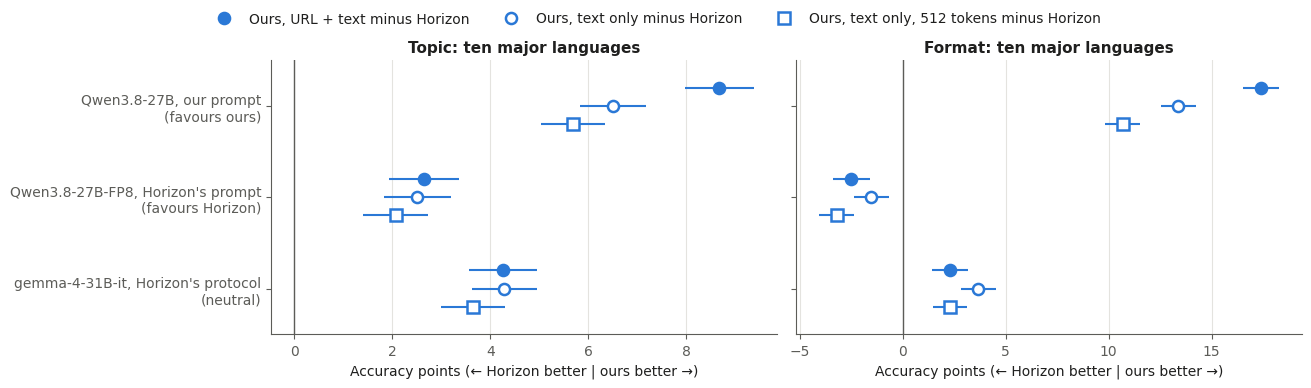

In [18]:
rows = []
for label_type in LABEL_TYPES:
    for labeller in LABELLERS:
        row = {"Label type": label_type, "Labeller": f"{LABELLERS[labeller]} ({LABELLER_FAVOURS[labeller]})"}
        for classifier in OURS:
            gain, half = paired_difference(MAJOR_SCORES[label_type, labeller, classifier],
                                           MAJOR_SCORES[label_type, labeller, HORIZON])
            row[f"{classifier} (points)"] = 100 * gain
            row[f"{classifier} ±"] = 100 * half
        ours, theirs = (MAJOR_SCORES[label_type, labeller, name] for name in ("Ours, text only, 512 tokens", HORIZON))
        for part in ("section 7 sample", "follow-up"):
            mask = ours["_counted"] & (MAJOR[label_type]["part"] == part)
            row[f"512 tokens, {part} only (points)"] = 100 * (ours["_correct"][mask].mean() - theirs["_correct"][mask].mean())
        rows.append(row)
MAJOR_DIFFERENCES = pd.DataFrame(rows)
display(MAJOR_DIFFERENCES.style.format({column: "{:+.1f}" for column in MAJOR_DIFFERENCES.columns if column.endswith("(points)")}
                                       | {column: "{:.1f}" for column in MAJOR_DIFFERENCES.columns if column.endswith("±")})
        .hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), layout="constrained", sharey=True)
for ax, label_type in zip(axes, LABEL_TYPES):
    frame = MAJOR_DIFFERENCES[MAJOR_DIFFERENCES["Label type"] == label_type].reset_index(drop=True)
    for y, row in frame.iterrows():
        for classifier in OURS:
            ax.errorbar(row[f"{classifier} (points)"], y + offsets[classifier], xerr=row[f"{classifier} ±"], ms=8,
                        elinewidth=1.5, linestyle="none", **marker_style(classifier))
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_yticks(range(len(frame)), [labeller.replace(" (", "\n(") for labeller in frame["Labeller"]])
    ax.set_ylim(len(frame) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Accuracy points (← Horizon better | ours better →)")
    ax.set_title(f"{label_type.capitalize()}: ten major languages")
fig.legend(handles=[Line2D([], [], ms=8, linestyle="none", label=f"{classifier} minus Horizon", **marker_style(classifier))
                    for classifier in OURS], loc="outside upper center", ncol=3)
plt.show()

### Per language

Ours minus Horizon per language, 1,150 pages each, with 95% intervals of the paired difference.
The figure shows the neutral judge (gemma-4-31B-it); the table counts languages for every
labeller; the last table lists every language and labeller.

Label type,Labeller,Ours,Ours clearly ahead,Not clearly different,Horizon clearly ahead
topic,"Qwen3.8-27B, our prompt (favours ours)","Ours, text only, 512 tokens",10,0,0
topic,"Qwen3.8-27B, our prompt (favours ours)","Ours, text only",10,0,0
topic,"Qwen3.8-27B-FP8, Horizon's prompt (favours Horizon)","Ours, text only, 512 tokens",5,5,0
topic,"Qwen3.8-27B-FP8, Horizon's prompt (favours Horizon)","Ours, text only",5,5,0
topic,"gemma-4-31B-it, Horizon's protocol (neutral)","Ours, text only, 512 tokens",9,1,0
topic,"gemma-4-31B-it, Horizon's protocol (neutral)","Ours, text only",9,1,0
format,"Qwen3.8-27B, our prompt (favours ours)","Ours, text only, 512 tokens",10,0,0
format,"Qwen3.8-27B, our prompt (favours ours)","Ours, text only",10,0,0
format,"Qwen3.8-27B-FP8, Horizon's prompt (favours Horizon)","Ours, text only, 512 tokens",0,4,6
format,"Qwen3.8-27B-FP8, Horizon's prompt (favours Horizon)","Ours, text only",0,8,2


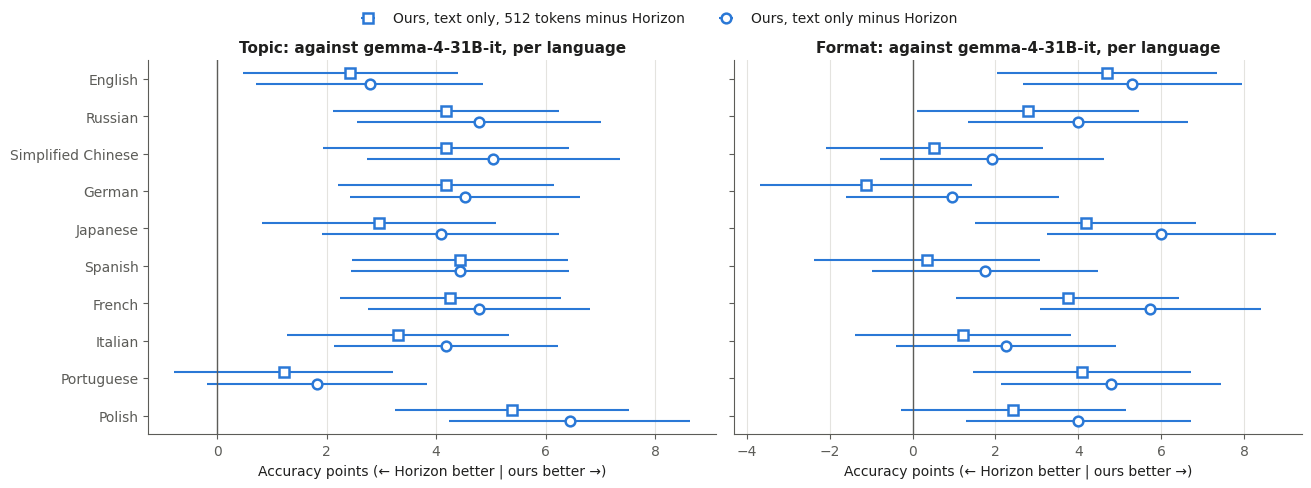

Ours (text only, 512 tokens) and Horizon per language and labeller

In [19]:
PER_LANGUAGE_CLASSIFIERS = ["Ours, text only, 512 tokens", "Ours, text only"]


def major_language_differences(label_type: str, labeller: str, classifier: str) -> pd.DataFrame:
    data = MAJOR[label_type]
    top = data["targets"][labeller].argmax(axis=1)
    counted = top < 24
    correct = data["predictions"][classifier] == top
    horizon_correct = data["predictions"][HORIZON] == top
    frame = pd.DataFrame({"language": data["language"][counted], "ours": correct[counted],
                          "horizon": horizon_correct[counted],
                          "difference": correct[counted].astype(float) - horizon_correct[counted].astype(float)})
    grouped = frame.groupby("language")
    table = pd.DataFrame({"Pages": grouped.size(), "Horizon": grouped["horizon"].mean(), "Ours": grouped["ours"].mean(),
                          "Difference": grouped["difference"].mean(),
                          "±": 1.96 * grouped["difference"].std(ddof=1) / np.sqrt(grouped.size())})
    return table.loc[MAJOR_LANGUAGES].set_axis([LANGUAGE_NAMES.get(language, language) for language in MAJOR_LANGUAGES])


rows, details = [], []
for label_type in LABEL_TYPES:
    for labeller in LABELLERS:
        for classifier in PER_LANGUAGE_CLASSIFIERS:
            table = major_language_differences(label_type, labeller, classifier)
            low, high = table["Difference"] - table["±"], table["Difference"] + table["±"]
            rows.append({"Label type": label_type, "Labeller": f"{LABELLERS[labeller]} ({LABELLER_FAVOURS[labeller]})",
                         "Ours": classifier, "Ours clearly ahead": int((low > 0).sum()),
                         "Not clearly different": int(((low <= 0) & (high >= 0)).sum()),
                         "Horizon clearly ahead": int((high < 0).sum())})
            if classifier == "Ours, text only, 512 tokens":
                details.append(table.assign(**{"Label type": label_type, "Labeller": LABELLERS[labeller]})
                               .set_index(["Label type", "Labeller"], append=True))
display(pd.DataFrame(rows).style.hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained", sharey=True)
language_offsets = dict(zip(PER_LANGUAGE_CLASSIFIERS, (-0.15, 0.15)))
for ax, label_type in zip(axes, LABEL_TYPES):
    for classifier in PER_LANGUAGE_CLASSIFIERS:
        table = major_language_differences(label_type, "gemma", classifier)
        y = np.arange(len(table)) + language_offsets[classifier]
        ax.errorbar(100 * table["Difference"], y, xerr=100 * table["±"], ms=7, elinewidth=1.5, linestyle="none",
                    label=f"{classifier} minus Horizon", **marker_style(classifier))
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_yticks(range(len(table)), table.index)
    ax.set_ylim(len(table) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Accuracy points (← Horizon better | ours better →)")
    ax.set_title(f"{label_type.capitalize()}: against gemma-4-31B-it, per language")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=2)
plt.show()

display(Markdown("Ours (text only, 512 tokens) and Horizon per language and labeller"))
MAJOR_LANGUAGE_TABLE = pd.concat(details).reorder_levels([1, 2, 0])
display(MAJOR_LANGUAGE_TABLE.style.format({"Horizon": "{:.1%}", "Ours": "{:.1%}", "Difference": "{:+.1%}", "±": "{:.1%}",
                                           "Pages": "{:,}"}))

**Reading section 8:**
- **Topic: ours is ahead against every labeller in all ten languages.** Like-for-like (text only,
  512 tokens): +5.7 (our prompt), +2.1 ± 0.7 (Horizon's prompt) and **+3.7 ± 0.6** (gemma)
  accuracy points; our text-only model at full length +4.3 ± 0.7 against gemma. Per language
  against gemma, ours is clearly ahead in nine (+2.4 for English to +5.4 for Polish); Portuguese
  (+1.2 ± 2.0) is not clearly different.
- **Format: ours is ahead against the neutral judge, Horizon against its own teacher.** Against
  gemma, +2.3 ± 0.8 at 512 tokens and +3.7 ± 0.8 at full length; ours clearly ahead in five
  languages at 512 tokens (English, Japanese, Portuguese, French, Russian) and six at full length,
  Horizon clearly ahead in none. Against Horizon's own prompt, Horizon leads by 3.2 ± 0.9 at 512
  tokens (clearly in six languages, most in Simplified Chinese, −7.1) and by 1.5 ± 0.9 at full
  length: the home advantage of matching the labels it was trained on.
- **The two samples agree:** against gemma, +4.1 / +3.6 (topic) and +1.5 / +2.4 (format) on the
  section 7 pages and on the follow-up pages.
- **The leads are smaller than over all 128 languages** for topic (section 7: +5.4 against gemma),
  as expected where Horizon had training data; for format the larger sample gives a slightly
  larger lead than section 7's +1.2.
- **The URL adds nothing against gemma** (topic +4.3 with or without it; format +2.3 with it,
  +3.7 without), as in section 7.

## 9. Summary

1. **Horizon's published English results reproduce** (within 1 and 7 pages of 3,000), so the
   comparison uses their model as released.
2. **On neutral labels our classifiers are ahead, clearly for topic and modestly for format.**
   - English, Llama-3.1-405B (WebOrganizer validation): like-for-like (text only, 512 tokens)
     +1.8 ± 0.6 (topic) and +4.3 ± 0.8 (format) accuracy points; our models as trained +3.6 and
     +9.3 (URL + text).
   - 128 languages, gemma-4-31B-it with Horizon's own judge protocol (19,200 pages of our test
     split): like-for-like +5.4 ± 0.6 (topic) and +1.2 ± 0.7 (format); our text-only model at full
     length +6.6 and +2.9.
   - **Ten major languages both systems were trained on** (English and FineWeb-2's nine largest;
     11,500 pages), gemma: like-for-like +3.7 ± 0.6 (topic) and +2.3 ± 0.8 (format); our text-only
     model at full length +4.3 and +3.7. Topic: ours clearly ahead in nine of ten languages;
     format: in five, Horizon in none.
3. **Against Horizon's own teacher labels** ours still leads on topic (+4.2 over 128 languages,
   +2.1 in the ten major languages) and trails on format (−1.9 and −3.2). **Against our own
   labels** the leads are much larger (+6 to +20 points), so most of the apparent format lead on
   our test split came from scoring with our prompt.
4. **The URL's benefit is tied to URL-aware labels:** it adds 2–4 points against our labels but
   nothing (topic) or slightly less than nothing (format) against URL-blind labellers. Cases like
   French escort spam that HPLT calls Occitan show the URL can be the right evidence; only human
   labels can say how often.
5. **Context length is a small part of the difference.** Cutting ours to 512 tokens costs 1.5
   (topic) and 3.8 (format) points against our labels, mostly on long pages.
6. **Coverage:** ours covers all 128 languages; against our labels its lead is smallest in large
   languages (+3 to +5 points) and largest in small ones Horizon was probably not trained on.
7. **Still open:** human labels on pages where the labellers disagree (especially format, and
   URL-dependent pages); a FineWeb-2 sample (Horizon's domain); Horizon's full training language
   list and their `llama_calib` pages.